# Data preparation: frozen eligible samples

Reconstruct the 2022–2023 residential samples from public discharge records. Membership was approved on September 20, 2026: 241,118 completion episodes and 146,194 frequency episodes. Missing covariates are imputed in six validation draws after the frozen sample is reconstructed; complete-case samples support sensitivity analyses.

## Files needed to run this notebook

Keep the `helper` folder beside this notebook. It contains:

- `outcomes.py`: matches admission substances to discharge slots and derives frequency outcomes.
- `balance.py`: computes covariate balance and effective sample sizes.
- `reporting.py`: assembles the tables, figures and stage timings into the HTML review written by the final cell.
- `run_notebook.py`: optional command-line runner that executes all cells, saves notebook outputs, and exports a full HTML report with execution status and cell runtimes.
- `assets/sample_specification.json`: fixed selection rules, covariates and verification hashes.
- `assets/completion_fold_reference.csv.gz` and `assets/frequency_fold_reference.csv.gz`: reference IDs, folds and scores used to verify reconstruction and preserve cross-fitting.
- `assets/evidence/`: saved historical tables and notebook inventory used by the decision-record notebook. Original sources remain in `notebooks/archive`.

Public source files are `data/interim/csv/tedsd_puf_2022.csv` and `tedsd_puf_2023.csv`, relative to the project root. Run from the project directory or its descendants. Python packages: numpy, pandas, matplotlib, scikit-learn, IPython, nbformat and nbconvert. Install these packages in the Python environment selected for the notebook.

Run all cells in order, or execute from the project root:

```sh
python S1/helper/run_notebook.py S1/S1_01_data_preparation.ipynb
```

Exports go to `outputs/` and timestamped HTML reviews to `reports/`. The sample rules and reference files are required inputs for this approved reconstruction.


In [1]:
from pathlib import Path
from datetime import datetime
import sys,json,hashlib,time,warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'configs/stage1_specifications.json').is_file())
HOME=ROOT/'S1'
HELPER=HOME/'helper'
sys.path.insert(0,str(HELPER))
from outcomes import derive_audit_fields,derive_frequency_outcomes
from balance import balance_table,weight_summary
from reporting import Review
SPEC=json.loads((HELPER/'assets/sample_specification.json').read_text())
FIELDS=SPEC['fields']
RUN_NAME='S1_01_data_preparation'
OUT=HOME/'outputs'/f'{RUN_NAME}_{datetime.now().astimezone():%Y%m%d_%H%M%S_%f}'
OUT.mkdir(parents=True)
review=Review(HOME/'reports',RUN_NAME)
review.note('# Scope\nReconstruct the frozen residential eligible samples and complete-case sensitivity samples from the public 2022–2023 discharge CSVs. Treatment is SERVICES5 versus4. Completion uses REASON1 versus2–7; frequency follows the admission substance to its unique discharge slot among baseline users. State–year membership rules and cross-fitting folds are frozen. These are overlap-population analyses in represented states; the six imputation validation draws are generated below; causal inference remains separate.')
print('Output directory:',OUT)


Output directory: /Users/researcher/code_projects/Causal Discovery /code/project_code/notebooks/code_0927/S1/outputs/S1_01_data_preparation_20260926_163212_739830


## 1. Source data and harmonization
Use 2022 and2023 as discharge cohorts. Missing source code−9 becomes NA. Race/ethnicity retain separate codes; additional-substance totals require both slots to be observed.

In [2]:
# Import only variables required for eligibility, outcomes and adjustment.
source_fields=[c for c in FIELDS if c!='additional_substances_total']
source_fields+=['SERVICES','REASON','SUB2','SUB3','METHUSE','DETCRIM']+[f'{v}{k}_D' for k in (1,2,3) for v in ('SUB','FREQ')]
DOMAINS={'SERVICES':range(1,9),'REASON':range(1,8),'FREQ1':[1,2,3],
         'RACE':range(1,10),'ETHNIC':range(1,6),'GENDER':[1,2],
         'NOPRIOR':[0,1],'PSYPROB':[1,2],'VET':[1,2],
         'FREQ_ATND_SELF_HELP':range(1,6)}
for slot in (1,2,3):
    DOMAINS[f'SUB{slot}']=range(1,20)
    DOMAINS[f'SUB{slot}_D']=range(1,20)
    DOMAINS[f'FREQ{slot}_D']=[1,2,3]
def prepare(raw,year,offset):
    d=raw.rename(columns={'SEX':'GENDER'}).copy()
    for col in d:d[col]=d[col].mask(d[col].eq(-9)).astype('Int64')
    for col,allowed in DOMAINS.items():
        assert (d[col].isna()|d[col].isin(allowed)).all(),f'Invalid codes: {col}'
    assert d.DISYR.notna().all() and d.DISYR.eq(year).all()
    d['episode_source_id']=[f'{year}:{i}' for i in range(offset+1,offset+len(d)+1)]
    # Unknown substance slots leave the total unknown; a known None counts as zero.
    extra=d[['SUB2','SUB3']]
    d['additional_substances_total']=extra.gt(1).fillna(False).sum(axis=1).astype('Int64').mask(extra.isna().any(axis=1))
    # The reason for being outside the labor force is structurally inapplicable
    # when employment status is known and not code4. Unknown EMPLOY stays unknown.
    d.loc[d.EMPLOY.notna()&d.EMPLOY.ne(4),'DETNLF']=0
    return d
# A small boundary check protects the additional-substance count.
extra=pd.DataFrame({'SUB2':[1,2,pd.NA],'SUB3':[1,1,2]},dtype='Int64')
count=extra.gt(1).fillna(False).sum(axis=1).mask(extra.isna().any(axis=1))
assert count.iloc[:2].tolist()==[0,1] and pd.isna(count.iloc[2])
pieces=[];raw_counts=[];source_hashes={}
for year in SPEC['years']:
    path=ROOT/f'data/interim/csv/tedsd_puf_{year}.csv'
    with path.open('rb') as stream:digest=hashlib.file_digest(stream,'sha256').hexdigest()
    assert digest==SPEC['raw_sha256'][str(path.relative_to(ROOT))],f'Source changed: {path}'
    source_hashes[str(path.relative_to(ROOT))]=digest
    header=pd.read_csv(path,nrows=0).columns
    columns=list(dict.fromkeys('SEX' if c=='GENDER' and 'GENDER' not in header else c for c in source_fields))
    offset=0;residential=0
    for raw in pd.read_csv(path,usecols=columns,chunksize=100000):
        d=prepare(raw,year,offset);offset+=len(raw)
        d=d.loc[d.SERVICES.isin([4,5])&d.SUB1.gt(1).fillna(False)].copy()
        d['treatment']=d.SERVICES.map({4:0,5:1}).astype('Int64')
        pieces.append(d);residential+=len(d)
    raw_counts.append({'year':year,'public_discharge_rows':offset,'residential_substance_episodes':residential})
data=pd.concat(pieces,ignore_index=True).set_index('episode_source_id')
assert data.index.is_unique
audit=derive_audit_fields(data);data[audit.columns]=audit
raw_counts=pd.DataFrame(raw_counts);display(raw_counts);review.table('Source population',raw_counts)
review.mark('Read and harmonize public CSVs')


,year,public_discharge_rows,residential_substance_episodes
0,2022,1394138,256037
1,2023,1474025,267613


## 2. Outcomes and approved membership
Completion is recorded program completion versus every other known discharge reason. Frequency reduction compares the same admission substance at discharge among baseline users; missing and ambiguous matches remain unclassified. These outcomes have different eligible populations.

In [3]:
# Compute outcome eligibility before complete-case selection.
# A missing or repeated substance match is audited rather than assigned abstinence.
match_count=sum(data.SUB1.eq(data[f'SUB{k}_D']).fillna(False).astype(int) for k in (1,2,3))
y_frequency=pd.Series(pd.NA,index=data.index,dtype='Int64')
frequency_change=pd.Series(pd.NA,index=data.index,dtype='Int64')
unique=data.loc[match_count.eq(1)]
frequency_derived=derive_frequency_outcomes(unique)
y_frequency.loc[unique.index]=frequency_derived.same_substance_frequency_reduction
frequency_change.loc[unique.index]=frequency_derived.same_substance_frequency_change
samples={};eligible_samples={};flows=[];availability=[];sensitivity_rows=[]
for outcome in ['completion','frequency']:
    rule=SPEC['samples'][outcome]
    allowed=set(map(tuple,rule['allowed_state_years']))
    in_cells=pd.Series([(int(s),int(y)) in allowed if pd.notna(s) else False for s,y in zip(data.STFIPS,data.DISYR)],index=data.index)
    d=data.loc[in_cells].copy()
    if outcome=='completion':
        target=d.REASON.isin(range(1,8)); observed=target
        y=d.REASON.eq(1).astype('Int64')
    else:
        target=d.REASON.isin([1,2,3,4,5,7])&d.FREQ1.isin([2,3])
        y=y_frequency.loc[d.index];observed=target&y.notna()
    complete=d[FIELDS].notna().all(axis=1)
    selected=observed&complete
    # Retain missing covariates in the frozen main-analysis population.
    eligible=d.loc[observed].copy()
    eligible['outcome']=y.loc[eligible.index].astype('Int64')
    if outcome=='frequency':eligible['frequency_change_3level']=frequency_change.loc[eligible.index].astype('Int64')
    eligible['complete_case']=complete.loc[eligible.index].astype(int)
    sensitivity_rows.extend([
        {'outcome':outcome,'definition':'primary_eligible','n':len(eligible)},
        {'outcome':outcome,'definition':'known_non_none_primary_substance','n':int(eligible.known_non_none_primary_substance.sum())},
        {'outcome':outcome,'definition':'partial_additional_substance_information','n':int(eligible.additional_substance_partial_information.sum())},
        {'outcome':outcome,'definition':'METHUSE_observed','n':int(eligible.METHUSE.notna().sum())},
        {'outcome':outcome,'definition':'DETCRIM_observed_when_PSOURCE_7','n':int((eligible.PSOURCE.eq(7)&eligible.DETCRIM.notna()).sum())},
    ])
    if outcome=='completion':sensitivity_rows.append({'outcome':outcome,'definition':'REASON_1_vs_2_3','n':int(eligible.completion_reason_1_vs_2_3.notna().sum())})
    else:
        for level,label in [(1,'improved'),(0,'unchanged'),(-1,'worsened')]:sensitivity_rows.append({'outcome':outcome,'definition':f'frequency_change_{label}','n':int(eligible.frequency_change_3level.eq(level).sum())})
    frozen=SPEC['frozen_eligible_samples']['outcomes'][outcome]
    membership_hash=hashlib.sha256(('\n'.join(sorted(eligible.index))+'\n').encode()).hexdigest()
    assert len(eligible)==frozen['n'] and membership_hash==frozen['membership_sha256']
    eligible_samples[outcome]=eligible
    for label,mask in [('approved_state_year_cells',pd.Series(True,index=d.index)),('outcome_target',target),('outcome_observed',observed),('complete_case',selected)]:
        flows.append({'outcome':outcome,'stage':label,'episodes':int(mask.sum())})
    for arm in [0,1]:
        a=d.treatment.eq(arm)
        availability.append({'outcome':outcome,'arm':arm,'target_n':int((a&target).sum()),'observed_n':int((a&observed).sum()),'complete_n':int((a&selected).sum())})
    sample=d.loc[selected,FIELDS+(['REASON'] if outcome=='completion' else [])+['treatment']].copy()
    sample['outcome']=y.loc[sample.index].astype('Int64')
    # Membership is derived above from raw fields, not selected by reference IDs.
    # The archived folds subsequently preserve the approved cross-fitting design.
    reference_path=HELPER/'assets'/rule['reference_file']
    assert hashlib.sha256(reference_path.read_bytes()).hexdigest()==rule['reference_sha256']
    reference=pd.read_csv(reference_path).set_index('episode_source_id')
    assert set(sample.index)==set(reference.index) and len(sample)==rule['n']
    sample=sample.loc[reference.index];sample['fold']=reference.fold
    canonical=sample.reset_index()[rule['record_columns']].sort_values('episode_source_id')
    for c in rule['record_columns'][1:]:canonical[c]=canonical[c].astype('Int64')
    assert hashlib.sha256(canonical.to_csv(index=False).encode()).hexdigest()==rule['records_sha256'],f'Raw reconstruction differs: {outcome}'
    samples[outcome]=sample
    print(outcome,len(sample),'rows: exact membership, covariates and outcomes reproduced')
flow=pd.DataFrame(flows);availability=pd.DataFrame(availability)
availability['observed_percent']=100*availability.observed_n/availability.target_n
display(flow);display(availability);review.table('Sequential sample flow',flow);review.table('Outcome availability before covariate restriction',availability)
sensitivity_audit=pd.DataFrame(sensitivity_rows)
flow.to_csv(OUT/'sample_flow.csv',index=False);availability.to_csv(OUT/'availability.csv',index=False);sensitivity_audit.to_csv(OUT/'sample_sensitivity_audit.csv',index=False)
review.table('Prespecified sensitivity and reporting audit',sensitivity_audit)
review.note('Race and ethnicity remain separate categorical variables. Self-help category5 denotes attendance with unknown frequency; it is retained as a category. The final covariate list excludes SERVICES (the treatment), METHUSE (potentially subsequent planning), LOS and discharge outcomes. DETNLF receives a structural0 only for known applicable employment states. The approved state–year table is an explicit design input, not a rule learned again from outcomes. No new exclusion is added when a diagnostic is flagged.')
review.mark('Derive outcomes, apply fixed rules and verify exact reconstruction')


completion 208421 rows: exact membership, covariates and outcomes reproduced
frequency 128605 rows: exact membership, covariates and outcomes reproduced


,outcome,stage,episodes
0,completion,approved_state_year_cells,241118
1,completion,outcome_target,241118
2,completion,outcome_observed,241118
3,completion,complete_case,208421
4,frequency,approved_state_year_cells,189913
5,frequency,outcome_target,149785
6,frequency,outcome_observed,146194
7,frequency,complete_case,128605


,outcome,arm,target_n,observed_n,complete_n,observed_percent
0,completion,0,163356,163356,140231,100.000000
1,completion,1,77762,77762,68190,100.000000
2,frequency,0,119067,116501,102149,97.844911
3,frequency,1,30718,29693,26456,96.663194


## 3. Complete-case sensitivity propensity scores
Five-fold fitting reproduces the complete-case reference scores. Eligible exports retain missing covariates and receive imputation-specific scores in Section 6.

In [4]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.exceptions import ConvergenceWarning
def fit_propensity(x,t,fold):
    design=x.astype(str).copy();cell=design.STFIPS+'|'+design.DISYR
    design['state_year']=cell
    for col in x:
        if col not in ['STFIPS','DISYR']:design['state_year_by_'+col]=cell+'|'+design[col]
    e=np.full(len(x),np.nan);audit=[]
    for f in range(5):
        train=fold!=f;test=fold==f
        assert set(t[train])==set(t[test])=={0,1}
        model=make_pipeline(OneHotEncoder(handle_unknown='ignore'),LogisticRegression(C=1,solver='lbfgs',max_iter=10000,tol=1e-6))
        began=time.perf_counter()
        with warnings.catch_warnings():
            warnings.simplefilter('error',ConvergenceWarning)
            model.fit(design.loc[train],t[train])
        e[test]=model.predict_proba(design.loc[test])[:,1]
        audit.append({'fold':f,'training_n':int(train.sum()),'evaluation_n':int(test.sum()),'iterations':int(model[-1].n_iter_[0]),'seconds':time.perf_counter()-began})
    assert np.isfinite(e).all() and ((e>0)&(e<1)).all()
    return e,audit
fit_audits=[]
for outcome,d in samples.items():
    print('Refitting',outcome,len(d),'episodes',flush=True)
    e,audit=fit_propensity(d[FIELDS],d.treatment.to_numpy(int),d.fold.to_numpy(int))
    reference=pd.read_csv(HELPER/'assets'/SPEC['samples'][outcome]['reference_file']).set_index('episode_source_id').loc[d.index]
    difference=float(np.max(np.abs(e-reference.propensity.to_numpy())))
    # Membership must match exactly; tiny numerical solver differences are allowed.
    np.testing.assert_allclose(e,reference.propensity.to_numpy(),rtol=0,atol=1e-5)
    d['propensity']=e;d['overlap_weight']=np.where(d.treatment.eq(1),1-e,e)
    fit_audits.extend(dict(outcome=outcome,**r) for r in audit)
    print('Maximum absolute difference from approved propensity:',difference)
fit_audits=pd.DataFrame(fit_audits);fit_audits.to_csv(OUT/'fold_audit.csv',index=False)
display(fit_audits);review.table('Five-fold fitting audit',fit_audits);review.mark('Refit propensity models for both outcomes')


Refitting completion 208421 episodes
Maximum absolute difference from approved propensity: 1.1102230246251565e-16
Refitting frequency 128605 episodes
Maximum absolute difference from approved propensity: 1.1102230246251565e-16


,outcome,fold,training_n,evaluation_n,iterations,seconds
0,completion,0,166759,41662,903,8.365249
1,completion,1,166576,41845,923,8.543128
2,completion,2,166840,41581,921,8.589667
3,completion,3,166601,41820,1007,9.387957
4,completion,4,166908,41513,938,8.649877
5,frequency,0,102882,25723,1131,6.254994
6,frequency,1,102892,25713,777,4.383412
7,frequency,2,102901,25704,1170,6.423172
8,frequency,3,102869,25736,1169,6.403881
9,frequency,4,102876,25729,1096,6.058068


## 4. Overlap, effective sample size and balance
Evaluate raw score tails alongside overlap-weighted balance and local support. A pooled balance statistic can conceal a local failure.

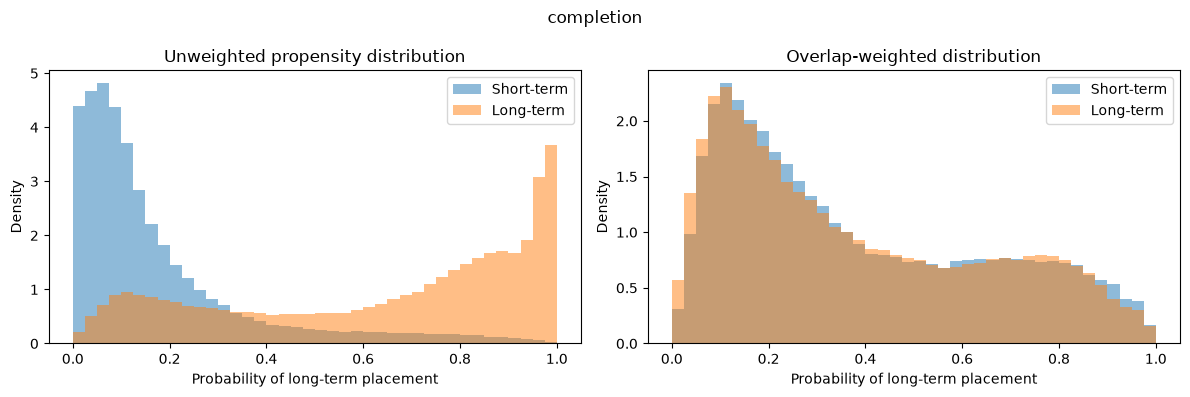

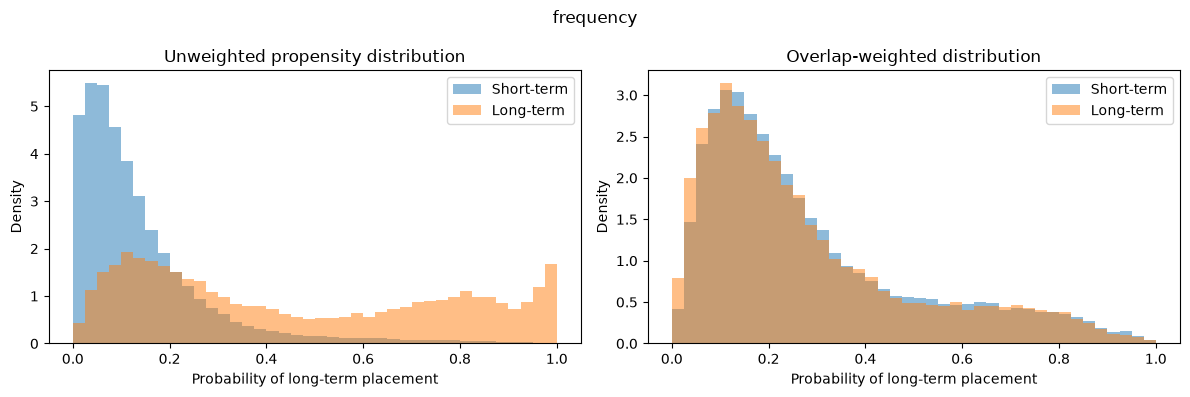

,outcome,n,states,max_absolute_smd,flagged_state_years,short_ess,long_ess
0,completion,208421,18,0.012629,0,65007.378949,39999.525116
1,frequency,128605,15,0.005038,1,49890.511933,19876.499591


,outcome,state,year,n,flagged_categories,minimum_arm_ess
0,completion,1,2022,2084,0,591.736739
1,completion,1,2023,2500,0,831.032723
2,completion,2,2022,648,0,89.798911
3,completion,8,2022,6294,0,1573.410572
4,completion,8,2023,1478,0,133.226725
5,completion,9,2022,3177,0,919.192537
6,completion,11,2022,600,0,114.267640
7,completion,17,2022,5051,0,1417.034833
8,completion,17,2023,10452,0,1410.030263
9,completion,19,2023,2190,0,359.674824


,outcome,arm,lower,upper,outside_episode_percent,outside_weight_percent
0,completion,Short-term,0.01,0.99,4.486169,0.194213
1,completion,Short-term,0.05,0.95,22.902924,4.600527
2,completion,Short-term,0.10,0.90,46.321427,16.513857
3,completion,Long-term,0.01,0.99,1.745124,0.340381
4,completion,Long-term,0.05,0.95,18.703622,5.959782
5,completion,Long-term,0.10,0.90,31.709928,17.920198
6,frequency,Short-term,0.01,0.99,5.152278,0.205038
7,frequency,Short-term,0.05,0.95,25.779009,5.051939
8,frequency,Short-term,0.10,0.90,50.896240,18.899437
9,frequency,Long-term,0.01,0.99,1.961748,0.550268


In [5]:
summaries=[];local_rows=[];intervals=[]
for outcome,d in samples.items():
    t=d.treatment.to_numpy(int);w=d.overlap_weight.to_numpy();e=d.propensity.to_numpy()
    x=pd.get_dummies(d[FIELDS].astype(str),dtype=float);balance=balance_table(x,t,w);ess=weight_summary(t,w)
    flagged=low=0
    for (state,year),idx in d.groupby(['STFIPS','DISYR']).indices.items():
        lb=balance_table(x.iloc[idx],t[idx],w[idx]);le=weight_summary(t[idx],w[idx])
        flag=lb.variable.map(x.iloc[idx].mean()).between(.05,.95)&lb.difference.abs().gt(.05)&(lb.abs_smd.gt(.1)|(lb.zero_reference_scale&lb.difference.abs().gt(1e-10)))
        flagged+=int(flag.any());low+=int(le.effective_sample_size.min()<50)
        local_rows.append({'outcome':outcome,'state':int(state),'year':int(year),'n':len(idx),'flagged_categories':int(flag.sum()),'minimum_arm_ess':le.effective_sample_size.min()})
    assert low==0
    assert flagged==(0 if outcome=='completion' else 1),f'Balance status changed: {outcome}'
    summaries.append({'outcome':outcome,'n':len(d),'states':d.STFIPS.nunique(),'max_absolute_smd':balance.abs_smd.max(),'flagged_state_years':flagged,'short_ess':ess.iloc[0].effective_sample_size,'long_ess':ess.iloc[1].effective_sample_size})
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for arm,label in [(0,'Short-term'),(1,'Long-term')]:
        mask=t==arm
        axes[0].hist(e[mask],bins=np.linspace(0,1,41),density=True,alpha=.5,label=label)
        axes[1].hist(e[mask],weights=w[mask],bins=np.linspace(0,1,41),density=True,alpha=.5,label=label)
        for cut in [.01,.05,.10]:
            tail=(e[mask]<cut)|(e[mask]>1-cut)
            intervals.append({'outcome':outcome,'arm':label,'lower':cut,'upper':1-cut,'outside_episode_percent':100*tail.mean(),'outside_weight_percent':100*w[mask][tail].sum()/w[mask].sum()})
    for ax,title in zip(axes,['Unweighted propensity distribution','Overlap-weighted distribution']):
        ax.set(title=title,xlabel='Probability of long-term placement',ylabel='Density');ax.legend()
    fig.suptitle(outcome);fig.tight_layout();image_path=OUT/f'{outcome}_overlap.png';fig.savefig(image_path,dpi=160);display(fig);plt.close(fig);review.figure(outcome+' propensity overlap',image_path)
    balance.to_csv(OUT/f'{outcome}_balance.csv',index=False)
summary=pd.DataFrame(summaries);local=pd.DataFrame(local_rows);tails=pd.DataFrame(intervals)
for name,d in [('summary',summary),('local_support',local),('propensity_intervals',tails)]:
    d.to_csv(OUT/f'{name}.csv',index=False);review.table(name,d);display(d)
review.note('Local flags require category prevalence5–95%, an absolute weighted gap above5 percentage points, and absolute SMD above0.10 (or a nonzero gap with zero reference variance). Completion has no flags under this rule. Frequency retains Louisiana2023 with two flagged categories. All retained state–year arms have ESS≥50. These criteria describe measured support, not all causal assumptions. No individual trimming, clipping or winsorizing is used.')
review.mark('Verify balance and support; plot overlap')


## 5. Export frozen eligible and complete-case samples
Eligible exports retain missing covariates, substance slots and observed outcomes. Complete-case exports retain their verified scores and folds. Membership is frozen before the imputation draws are generated. Inferential validation remains separate.

In [6]:
outputs={}
for outcome,d in samples.items():
    path=OUT/f'{outcome}_final_complete_case.csv.gz'
    d.to_csv(path,index_label='episode_source_id',compression={'method':'gzip','mtime':0})
    reread=pd.read_csv(path).set_index('episode_source_id')
    assert list(reread.index)==list(d.index) and len(reread)==SPEC['samples'][outcome]['n']
    np.testing.assert_allclose(reread.propensity,d.propensity)
    outputs[path.name]={'n':len(d),'sha256':hashlib.sha256(path.read_bytes()).hexdigest()}
for outcome,d in eligible_samples.items():
    path=OUT/f'{outcome}_final_eligible.csv.gz'
    d.to_csv(path,index_label='episode_source_id',compression={'method':'gzip','mtime':0})
    reread=pd.read_csv(path,index_col='episode_source_id')
    assert reread.index.equals(d.index) and len(reread)==SPEC['frozen_eligible_samples']['outcomes'][outcome]['n']
    for field in FIELDS:
        assert reread[field].isna().equals(d[field].isna())
    assert reread.outcome.notna().all() and reread.treatment.notna().all()
    outputs[path.name]={'n':len(d),'sha256':hashlib.sha256(path.read_bytes()).hexdigest(),'role':'frozen eligible population; missing covariates retained'}
manifest={'status':'verified_raw_reconstruction','source_hashes':source_hashes,'specification_sha256':hashlib.sha256((HELPER/'assets/sample_specification.json').read_bytes()).hexdigest(),'outputs':outputs,'audit_artifacts':{'sample_sensitivity_audit.csv':hashlib.sha256((OUT/'sample_sensitivity_audit.csv').read_bytes()).hexdigest()},'scope':'Frozen eligible membership unchanged; prespecified audit and sensitivity fields are descriptive until separately analyzed','trimming':False,'winsorizing':False}
(OUT/'manifest.json').write_text(json.dumps(manifest,indent=2)+'\n')
review.table('Saved samples',pd.DataFrame([dict(file=k,**v) for k,v in outputs.items()]))
review.mark('Save and reload final samples')
print('Frozen sample exports:',OUT)


Frozen sample exports: /Users/researcher/code_projects/Causal Discovery /code/project_code/notebooks/code_0927/S1/outputs/S1_01_data_preparation_20260926_163212_739830


## 6. Imputation draws for the frozen eligible samples

Generate two ten-iteration chained-imputation draws for completion (seed 722) and four for frequency (seeds 720 and 721). This is the established validation procedure recorded in `S1_01A_data_preparation_record.ipynb`; it preserves observed fields and the frozen episode membership, then refits propensity scores within each draw. The draw and balance checks prepare inputs for `S1_01_02_residential_outcome_review.ipynb`. Two or four draws do not establish imputation convergence or valid uncertainty estimates.


In [7]:
def validate_imputation(chain_sample, OUT, seed):
    from sklearn.model_selection import StratifiedKFold
    chain_fields=[f for f in FIELDS if f not in ['EMPLOY','DETNLF']]+['employment_joint','treatment','outcome']
    base=chain_sample[[f for f in chain_fields if f!='employment_joint']].astype(float)
    base['employment_joint']=(10*chain_sample.EMPLOY).astype(float)
    parent_four=chain_sample.EMPLOY.eq(4).fillna(False)
    base.loc[parent_four,'employment_joint']=(40+chain_sample.loc[parent_four,'DETNLF']).astype(float)
    base=base[chain_fields]
    slots=chain_sample[['SUB2','SUB3']]
    lower=slots.gt(1).fillna(False).sum(axis=1).to_numpy();upper=lower+slots.isna().sum(axis=1).to_numpy()
    def feasible(field,classes,rows):
        vals=np.asarray(classes);result=np.ones((len(rows),len(vals)),dtype=bool)
        if field=='additional_substances_total':result=(vals[None,:]>=lower[rows,None])&(vals[None,:]<=upper[rows,None])
        if field=='employment_joint':
            parent=chain_sample.EMPLOY.to_numpy(dtype=float,na_value=np.nan)[rows]
            detail=chain_sample.DETNLF.to_numpy(dtype=float,na_value=np.nan)[rows]
            result&=np.isnan(parent[:,None])|(vals[None,:]//10==parent[:,None])
            known=np.isfinite(detail)&(detail>0)
            result[known]&=vals[None,:]==(40+detail[known,None])
            result[np.isfinite(detail)&(detail==0)]&=vals[None,:]<40
        return result
    # Independent repeat of the saved seed-720 validation; sample rules and folds stay fixed.
    rng=np.random.default_rng(seed);targets=base.columns[base.isna().any()].tolist();chain_rows=[];chain_balance=[];chain_traces=[];chain_local=[]
    fold=np.full(len(base),-1)
    for k,(_,idx) in enumerate(StratifiedKFold(5,shuffle=True,random_state=720).split(base,base.treatment)):fold[idx]=k
    for chain in range(2):
        print('Full-population chain',chain+1,'of 2',flush=True)
        start=time.perf_counter();z=base.copy()
        for field in targets:
            classes,counts=np.unique(base[field].dropna(),return_counts=True);rows=np.flatnonzero(base[field].isna())
            prob=feasible(field,classes,rows)*counts[None,:]
            assert (prob.sum(axis=1)>0).all(),field
            prob=prob/prob.sum(axis=1)[:,None]
            z.loc[base[field].isna(),field]=[rng.choice(classes,p=r) for r in prob]
        for iteration in range(10):
            print('Chain',chain+1,'iteration',iteration+1,'of 10',flush=True)
            for field in targets:
                observed=base[field].notna();rows=np.flatnonzero(~observed)
                x=z.drop(columns=field).astype(str);x['state_year']=x.STFIPS+'|'+x.DISYR;x['treatment_outcome']=x.treatment+'|'+x.outcome
                classes=np.sort(base.loc[observed,field].unique())
                if len(classes)==1:prob=np.ones((len(rows),1))
                else:
                    model=make_pipeline(OneHotEncoder(handle_unknown='ignore'),LogisticRegression(C=1,max_iter=2000))
                    w=rng.exponential(size=observed.sum());w/=w.mean()
                    with warnings.catch_warnings():
                        warnings.simplefilter('error',ConvergenceWarning)
                        model.fit(x.loc[observed],base.loc[observed,field].astype(int),logisticregression__sample_weight=w)
                    classes=model[-1].classes_;prob=model.predict_proba(x.loc[~observed])
                prob*=feasible(field,classes,rows);assert (prob.sum(axis=1)>0).all(),field
                prob/=prob.sum(axis=1)[:,None]
                z.loc[~observed,field]=[rng.choice(classes,p=r) for r in prob]
            for field in targets:
                missing_mask=base[field].isna()
                for category,share in z.loc[missing_mask,field].value_counts(normalize=True).items():
                    chain_traces.append(dict(chain=chain+1,iteration=iteration+1,field=field,category=category,share=share))
            assert not z.isna().any().any()
            for field in base:
                obs=base[field].notna();assert np.array_equal(z.loc[obs,field],base.loc[obs,field])
            assert z.employment_joint.isin([10,20,30,41,42,43,44,45]).all()
            assert z.additional_substances_total.between(lower,upper).all()
        complete=z.copy();complete['EMPLOY']=complete.employment_joint//10
        complete['DETNLF']=np.where(complete.EMPLOY.eq(4),complete.employment_joint%10,0)
        for field in ['EMPLOY','DETNLF']:
            obs=chain_sample[field].notna();assert np.array_equal(complete.loc[obs,field],chain_sample.loc[obs,field].astype(float))
        e,_=fit_propensity(complete[FIELDS],complete.treatment.to_numpy(int),fold)
        w=np.where(complete.treatment.eq(1),1-e,e)
        b=balance_table(pd.get_dummies(complete[FIELDS].astype(str),dtype=float),complete.treatment,w)
        b['chain']=chain+1;chain_balance.append(b)
        for (state,year),g in complete.groupby(['STFIPS','DISYR']):
            positions=complete.index.get_indexer(g.index);local_w=w[positions]
            lx=pd.get_dummies(g[FIELDS].astype(str),dtype=float)
            lb=balance_table(lx,g.treatment,local_w)
            prevalence=lx.mean().reindex(lb.variable).to_numpy()
            flag=(prevalence>=.05)&(prevalence<=.95)&lb.difference.abs().gt(.05)&(lb.abs_smd.gt(.1)|(lb.zero_reference_scale&lb.difference.ne(0)))
            support=weight_summary(g.treatment,local_w)
            chain_local.append(dict(chain=chain+1,state=state,year=year,n=len(g),flagged_categories=int(flag.sum()),minimum_arm_ess=support.effective_sample_size.min()))
        ess=weight_summary(complete.treatment,w)
        chain_rows.append(dict(chain=chain+1,n=len(complete),iterations=10,max_abs_smd=b.abs_smd.max(),outside_005_095_percent=100*((e<.05)|(e>.95)).mean(),short_ess=ess.loc[ess.treatment.eq(0),'effective_sample_size'].iloc[0],long_ess=ess.loc[ess.treatment.eq(1),'effective_sample_size'].iloc[0],seconds=time.perf_counter()-start))
        complete['propensity']=e;complete['overlap_weight']=w
        complete.to_csv(OUT/f'engineering_imputation_chain_{chain+1}.csv.gz',index_label='episode_source_id')
    chain_summary=pd.DataFrame(chain_rows)
    display(chain_summary);review.table('Full-population chained-imputation validation',chain_summary)
    review.note('All observed values and both structural constraints were checked in the eligible episodes. Two ten-iteration chains assess implementation and balance; uncertainty calibration and chain stability require separate review.')
    traces=pd.DataFrame(chain_traces)
    local_checks=pd.DataFrame(chain_local)
    display(local_checks);review.table('Full-population local support and balance',local_checks)
    # Compare categorical shares using common columns, including categories absent in a draw.
    wide=traces.pivot_table(index=['chain','iteration'],columns=['field','category'],values='share',fill_value=0)
    changes=[]
    for chain in [1,2]:
        block=wide.loc[chain];last=block.loc[6:10]
        changes.append(dict(chain=chain,max_category_share_change_2_to_10=(block.loc[10]-block.loc[2]).abs().max(),max_category_share_range_last5=(last.max()-last.min()).max()))
    stability=pd.DataFrame(changes)
    display(stability);review.table('Categorical trace stability',stability)
    review.note('Local ESS and balance refer to the full eligible observed-outcome population. Category-share traces describe ten iterations; convergence and inferential validity remain separate checks.')
    review.mark('Run constrained chained-imputation validation')
    return dict(base=base, targets=targets, fold=fold, wide=wide, traces=traces)


In [8]:
imputation_runs={'completion':[722],'frequency':[720,721]}
for outcome,seeds in imputation_runs.items():
    for seed in seeds:
        folder=OUT/f'{outcome}_imputation_seed{seed}'
        folder.mkdir()
        review.note(f'## {outcome} imputation, seed {seed}')
        validate_imputation(eligible_samples[outcome],folder,seed)
        for chain in (1,2):
            path=folder/f'engineering_imputation_chain_{chain}.csv.gz'
            draw=pd.read_csv(path,index_col='episode_source_id')
            assert draw.index.equals(eligible_samples[outcome].index)
            np.testing.assert_array_equal(draw.outcome.to_numpy(int),eligible_samples[outcome].outcome.to_numpy(int))
            np.testing.assert_array_equal(draw.treatment.to_numpy(int),eligible_samples[outcome].treatment.to_numpy(int))
            np.testing.assert_allclose(draw.overlap_weight,np.where(draw.treatment.eq(1),1-draw.propensity,draw.propensity),rtol=0,atol=1e-10)
            outputs[str(path.relative_to(OUT))]={'n':len(draw),'sha256':hashlib.sha256(path.read_bytes()).hexdigest(),'seed':seed,'chain':chain}
manifest['status']='verified_samples_and_imputation_draws'
manifest['scope']='Frozen eligible membership and six imputation validation draws; imputation uncertainty and causal inference pending'
manifest['imputation']={'runs':imputation_runs,'chains_per_seed':2,'iterations_per_chain':10}
manifest['outputs']=outputs
(OUT/'manifest.json').write_text(json.dumps(manifest,indent=2)+'\n')
review.table('Saved imputation draws',pd.DataFrame([dict(file=k,**v) for k,v in outputs.items() if 'imputation_seed' in k]))
review.mark('Verify six draw files and update manifest')
print('S1_02 inputs:',OUT)


Full-population chain 1 of 2
Chain 1 iteration 1 of 10
Chain 1 iteration 2 of 10
Chain 1 iteration 3 of 10
Chain 1 iteration 4 of 10
Chain 1 iteration 5 of 10
Chain 1 iteration 6 of 10
Chain 1 iteration 7 of 10
Chain 1 iteration 8 of 10
Chain 1 iteration 9 of 10
Chain 1 iteration 10 of 10
Full-population chain 2 of 2
Chain 2 iteration 1 of 10
Chain 2 iteration 2 of 10
Chain 2 iteration 3 of 10
Chain 2 iteration 4 of 10
Chain 2 iteration 5 of 10
Chain 2 iteration 6 of 10
Chain 2 iteration 7 of 10
Chain 2 iteration 8 of 10
Chain 2 iteration 9 of 10
Chain 2 iteration 10 of 10
Full-population chain 1 of 2
Chain 1 iteration 1 of 10
Chain 1 iteration 2 of 10
Chain 1 iteration 3 of 10
Chain 1 iteration 4 of 10
Chain 1 iteration 5 of 10
Chain 1 iteration 6 of 10
Chain 1 iteration 7 of 10
Chain 1 iteration 8 of 10
Chain 1 iteration 9 of 10
Chain 1 iteration 10 of 10
Full-population chain 2 of 2
Chain 2 iteration 1 of 10
Chain 2 iteration 2 of 10
Chain 2 iteration 3 of 10
Chain 2 iteration 4 of 

,chain,n,iterations,max_abs_smd,outside_005_095_percent,short_ess,long_ess,seconds
0,1,241118,10,0.009213,21.658690,76092.097159,47195.666987,1171.143201
1,2,241118,10,0.008974,21.588185,76123.898178,47183.916419,1170.056497


,chain,state,year,n,flagged_categories,minimum_arm_ess
0,1,1.0,2022.0,2669,0,820.164673
1,1,1.0,2023.0,3305,0,1042.742728
2,1,2.0,2022.0,1032,0,160.013406
3,1,8.0,2022.0,8229,0,1884.085717
4,1,8.0,2023.0,2253,0,178.373663
5,1,9.0,2022.0,5617,0,1883.337178
6,1,11.0,2022.0,1239,0,184.032816
7,1,17.0,2022.0,5535,0,1628.633746
8,1,17.0,2023.0,12316,0,1606.744503
9,1,19.0,2023.0,6045,0,667.237805


,chain,max_category_share_change_2_to_10,max_category_share_range_last5
0,1,0.040493,0.062235
1,2,0.052632,0.052632


,chain,n,iterations,max_abs_smd,outside_005_095_percent,short_ess,long_ess,seconds
0,1,146194,10,0.004098,23.756105,56231.790919,22786.916112,697.780671
1,2,146194,10,0.004091,23.766365,56234.193230,22786.097915,698.905321


,chain,state,year,n,flagged_categories,minimum_arm_ess
0,1,1.0,2022.0,1200,0,398.078014
1,1,1.0,2023.0,1485,0,484.392324
2,1,2.0,2022.0,828,0,141.520120
3,1,8.0,2022.0,6514,0,1280.916769
4,1,9.0,2022.0,4086,0,1452.716194
5,1,11.0,2022.0,902,0,123.779824
6,1,17.0,2022.0,2205,0,663.883814
7,1,17.0,2023.0,7518,0,467.074115
8,1,19.0,2023.0,4520,0,235.965526
9,1,21.0,2022.0,3568,0,511.684015


,chain,max_category_share_change_2_to_10,max_category_share_range_last5
0,1,0.090909,0.212121
1,2,0.033510,0.090909


,chain,n,iterations,max_abs_smd,outside_005_095_percent,short_ess,long_ess,seconds
0,1,146194,10,0.00403,23.777994,56223.831363,22779.346727,701.883434
1,2,146194,10,0.00398,23.736952,56257.258769,22766.986379,683.561826


,chain,state,year,n,flagged_categories,minimum_arm_ess
0,1,1.0,2022.0,1200,0,399.599050
1,1,1.0,2023.0,1485,0,482.827868
2,1,2.0,2022.0,828,0,141.919298
3,1,8.0,2022.0,6514,0,1280.975912
4,1,9.0,2022.0,4086,0,1440.748368
5,1,11.0,2022.0,902,0,124.116255
6,1,17.0,2022.0,2205,0,664.512039
7,1,17.0,2023.0,7518,0,466.178276
8,1,19.0,2023.0,4520,0,235.831406
9,1,21.0,2022.0,3568,0,514.022010


,chain,max_category_share_change_2_to_10,max_category_share_range_last5
0,1,0.033510,0.151515
1,2,0.090909,0.212121


## Propensity figures for the fixed eligible samples

Each outcome uses the first saved imputation validation draw, with the exact frozen episode membership. The left panel shows the score distribution within each treatment arm before weighting; the right panel shows the same episodes after overlap weighting. Each arm is normalized separately, so panel height is a density rather than the number of episodes. Dotted lines mark scores 0.05 and 0.95 as descriptive tail guides. These plots describe measured treatment overlap and the population emphasized by the weights. State–year balance and imputation diagnostics are assessed separately.

HTML review: /Users/researcher/code_projects/Causal Discovery /code/project_code/notebooks/code_0927/S1/reports/S1_01_data_preparation_20260926_175953_190478.html
Propensity figures: ['completion_propensity_eligible_draw1.png', 'frequency_propensity_eligible_draw1.png']


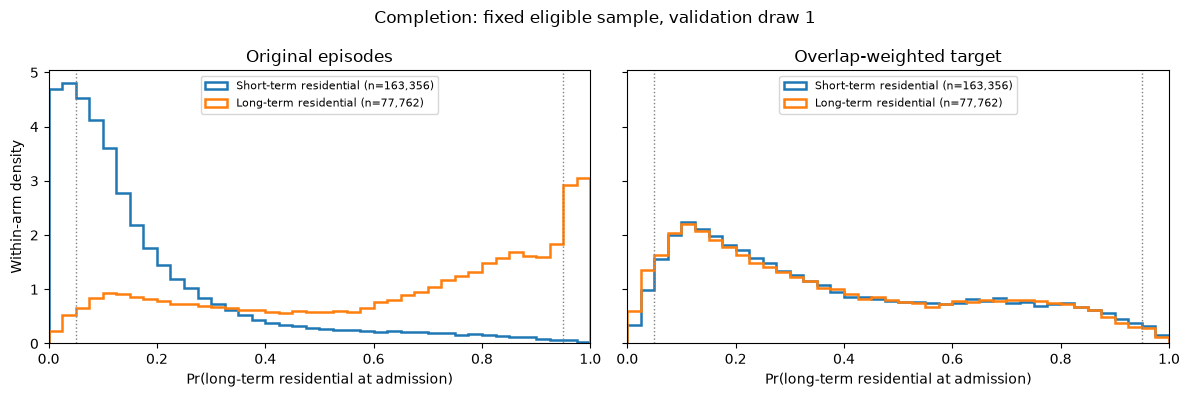

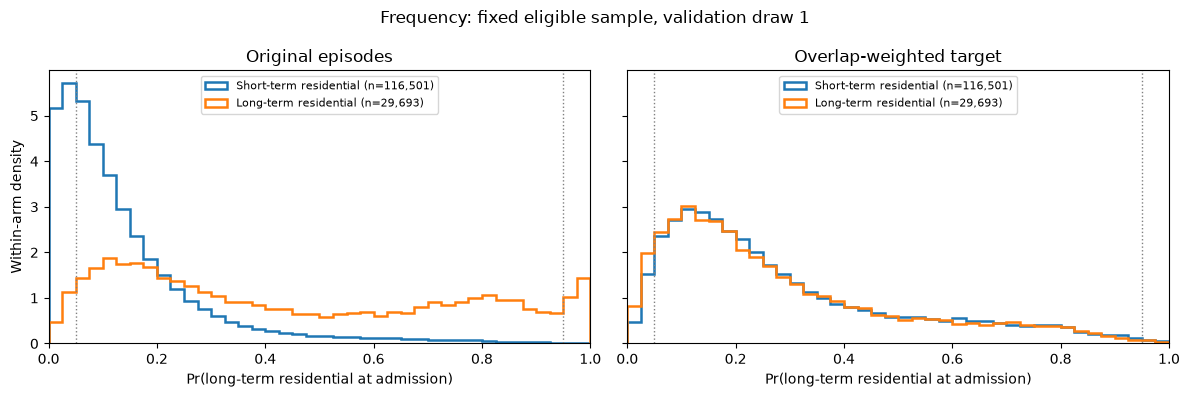

In [9]:
from balance import plot_propensity_distributions
import matplotlib.pyplot as plt
figures=[]
for outcome,seed in (('completion',722),('frequency',720)):
    eligible=pd.read_csv(OUT/f'{outcome}_final_eligible.csv.gz',usecols=['episode_source_id','treatment'])
    source=OUT/f'{outcome}_imputation_seed{seed}/engineering_imputation_chain_1.csv.gz'
    draw=pd.read_csv(source,usecols=['episode_source_id','treatment','propensity','overlap_weight'])
    assert len(draw)==len(eligible) and draw.episode_source_id.equals(eligible.episode_source_id)
    np.testing.assert_array_equal(draw.treatment.to_numpy(),eligible.treatment.to_numpy())
    np.testing.assert_allclose(draw.overlap_weight,np.where(draw.treatment.eq(1),1-draw.propensity,draw.propensity),rtol=0,atol=1e-10)
    fig=plot_propensity_distributions(draw.propensity,draw.treatment,draw.overlap_weight,
        labels=('Short-term residential','Long-term residential'),title=f'{outcome.title()}: fixed eligible sample, validation draw 1',
        score_label='Pr(long-term residential at admission)')
    image_path=OUT/f'{outcome}_propensity_eligible_draw1.png'
    fig.savefig(image_path,dpi=160)
    display(fig);plt.close(fig)
    review.figure(f'{outcome} eligible-sample propensity distributions',image_path)
    figures.append({'outcome':outcome,'file':image_path.name,'source_draw':str(source.relative_to(OUT)),
                    'n':len(draw),'sha256':hashlib.sha256(image_path.read_bytes()).hexdigest()})
manifest['propensity_figures']=figures
(OUT/'manifest.json').write_text(json.dumps(manifest,indent=2)+'\n')
review.mark('Verify fixed eligible membership and export propensity figures')
report_path=review.export();print('HTML review:',report_path)
print('Propensity figures:',[item['file'] for item in figures])